<a href="https://colab.research.google.com/github/sshafika-code/ecommerce-sales-analyzer-/blob/main/ecommerce_sales_analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 120  |  Products: 20

--- By Category ---
              Revenue  Total_Cost   Profit
Category                                 
Accessories  1904100      987800   916300
Clothing     1272400      798300   474100
Electronics  8067800     6547700  1520100

--- Monthly ---
        Revenue  Profit
Month                 
Jan    1890150  497880
Feb    1805650  472290
Mar    1911600  494060
Apr    1860150  473380
May    1763450  464100
Jun    2013300  508790

Most profitable: Smartphone 490000
Biggest loss: Dress -24600


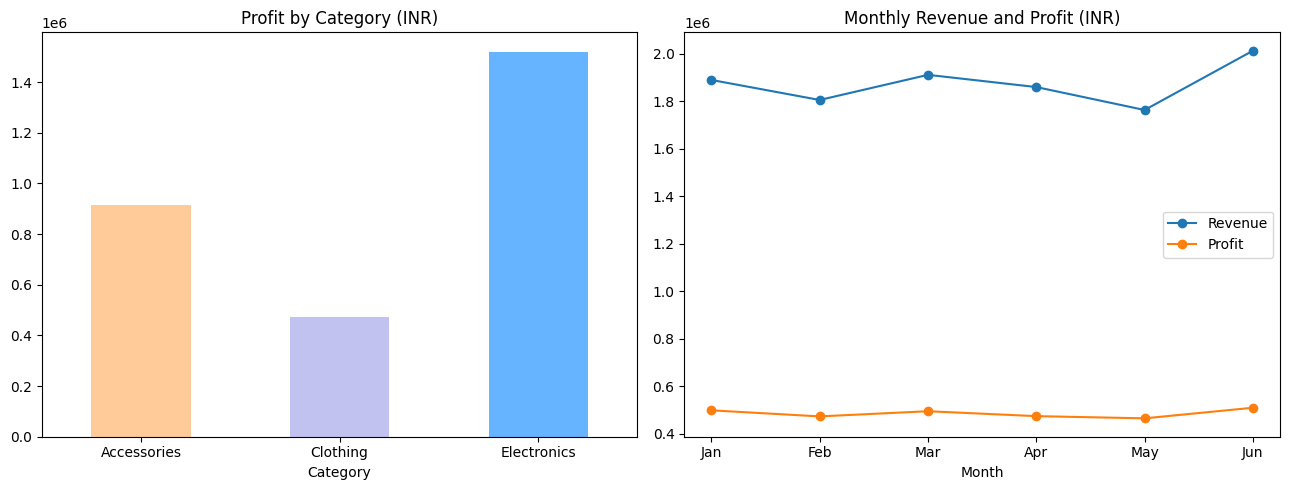


Saved: sales_data.csv, charts.png, sales_report.xlsx


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import Workbook
from openpyxl.chart import BarChart, LineChart, Reference
from openpyxl.styles import Font, PatternFill, Alignment

# ---------- 1. Sample data (made up for practice) ----------
# (Product_ID, Product_Name, Category, Cost_INR, Price_INR, Base_Monthly_Qty)
products = [
    (101, "Laptop", "Electronics", 52000, 60000, 5),
    (102, "Smartphone", "Electronics", 38000, 45000, 12),
    (103, "Monitor", "Electronics", 12000, 15000, 8),
    (104, "Tablet", "Electronics", 20000, 26000, 7),
    (105, "Smartwatch", "Electronics", 4500, 7000, 10),
    (106, "Camera", "Electronics", 30000, 38000, 3),
    (107, "Speaker", "Electronics", 1800, 3200, 14),
    (108, "Headphones", "Accessories", 1800, 3000, 40),
    (109, "Keyboard", "Accessories", 1500, 2500, 25),
    (110, "Mouse", "Accessories", 400, 800, 45),
    (111, "Phone Case", "Accessories", 120, 400, 80),
    (112, "Charger", "Accessories", 350, 700, 50),
    (113, "Laptop Bag", "Accessories", 900, 1800, 20),
    (114, "USB Cable", "Accessories", 80, 250, 90),
    (115, "T-Shirt", "Clothing", 250, 600, 60),
    (116, "Jeans", "Clothing", 900, 1800, 30),
    (117, "Saree", "Clothing", 1500, 3000, 18),
    (118, "Dress", "Clothing", 1400, 1200, 22),      # sold below cost (clearance)
    (119, "Costume", "Clothing", 2200, 1900, 10),    # sold below cost (clearance)
    (120, "Jacket", "Clothing", 1600, 2800, 12),
]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]

rng = np.random.default_rng(42)
rows = []
for m in months:
    for pid, name, cat, cost, price, base in products:
        qty = max(1, int(base * rng.uniform(0.7, 1.3)))
        rows.append([m, pid, name, cat, cost, price, qty])

df = pd.DataFrame(rows, columns=["Month", "Product_ID", "Product_Name", "Category",
                                 "Cost_INR", "Price_INR", "Quantity_Sold"])

# ---------- 2. Revenue, cost, profit ----------
df["Revenue"] = df["Price_INR"] * df["Quantity_Sold"]
df["Total_Cost"] = df["Cost_INR"] * df["Quantity_Sold"]
df["Profit"] = df["Revenue"] - df["Total_Cost"]
df["Status"] = np.where(df["Profit"] >= 0, "Profit", "Loss")
df.to_csv("sales_data.csv", index=False)
print(f"Rows: {len(df)}  |  Products: {df['Product_ID'].nunique()}")

# ---------- 3. Analysis ----------
by_cat = df.groupby("Category")[["Revenue", "Total_Cost", "Profit"]].sum()
print("\n--- By Category ---\n", by_cat)

monthly = df.groupby("Month")[["Revenue", "Profit"]].sum().reindex(months)
print("\n--- Monthly ---\n", monthly)

by_product = df.groupby("Product_Name")["Profit"].sum().sort_values()
print("\nMost profitable:", by_product.idxmax(), by_product.max())
print("Biggest loss:", by_product.idxmin(), by_product.min())

# ---------- 4. Charts (saved as images for GitHub) ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
by_cat["Profit"].plot(kind="bar", ax=axes[0], color=["#ffcc99", "#c2c2f0", "#66b3ff"])
axes[0].set_title("Profit by Category (INR)")
axes[0].tick_params(axis="x", rotation=0)
monthly.plot(ax=axes[1], marker="o")
axes[1].set_title("Monthly Revenue and Profit (INR)")
plt.tight_layout()
plt.savefig("charts.png")
plt.show()

# ---------- 5. Excel report (uses formulas, so it updates itself) ----------
wb = Workbook()
ws = wb.active
ws.title = "Sales Data"
headers = ["Month", "Product_ID", "Product_Name", "Category", "Cost_INR",
           "Price_INR", "Quantity_Sold", "Revenue", "Total_Cost", "Profit", "Status"]
ws.append(headers)
for i, r in enumerate(df[headers[:7]].itertuples(index=False), start=2):
    ws.append(list(r) + [f"=F{i}*G{i}", f"=E{i}*G{i}", f"=H{i}-I{i}",
                         f'=IF(J{i}>=0,"Profit","Loss")'])
last = len(df) + 1

head_fill = PatternFill("solid", fgColor="1F4E78")
for c in ws[1]:
    c.font = Font(name="Arial", bold=True, color="FFFFFF")
    c.fill = head_fill
    c.alignment = Alignment(horizontal="center")
for row in ws.iter_rows(min_row=2):
    for c in row:
        c.font = Font(name="Arial")
for col, w in zip("ABCDEFGHIJK", [8, 11, 15, 13, 10, 10, 14, 12, 12, 12, 9]):
    ws.column_dimensions[col].width = w
for row in ws.iter_rows(min_row=2, min_col=5, max_col=10):
    for c in row:
        c.number_format = '#,##0;[Red]-#,##0'
ws.freeze_panes = "A2"

sm = wb.create_sheet("Summary")
sm["A1"] = "E-Commerce Sales Summary (sample data)"
sm["A1"].font = Font(name="Arial", bold=True, size=14)

sm.append([])
sm.append(["Category", "Revenue", "Total_Cost", "Profit"])        # row 3
cats = ["Electronics", "Accessories", "Clothing"]
for i, cat in enumerate(cats, start=4):
    sm.append([cat,
               f"=SUMIFS('Sales Data'!$H$2:$H${last},'Sales Data'!$D$2:$D${last},$A{i})",
               f"=SUMIFS('Sales Data'!$I$2:$I${last},'Sales Data'!$D$2:$D${last},$A{i})",
               f"=SUMIFS('Sales Data'!$J$2:$J${last},'Sales Data'!$D$2:$D${last},$A{i})"])
sm.append(["Total", "=SUM(B4:B6)", "=SUM(C4:C6)", "=SUM(D4:D6)"])   # row 7

sm["A9"], sm["B9"], sm["C9"] = "Month", "Revenue", "Profit"
for i, m in enumerate(months, start=10):
    sm[f"A{i}"] = m
    sm[f"B{i}"] = f"=SUMIFS('Sales Data'!$H$2:$H${last},'Sales Data'!$A$2:$A${last},$A{i})"
    sm[f"C{i}"] = f"=SUMIFS('Sales Data'!$J$2:$J${last},'Sales Data'!$A$2:$A${last},$A{i})"

for ref in ("A3:D3", "A9:C9"):
    for row in sm[ref]:
        for c in row:
            c.font = Font(name="Arial", bold=True, color="FFFFFF")
            c.fill = head_fill
for row in sm["A4:D15"]:
    for c in row:
        c.font = Font(name="Arial", bold=(c.row == 7))
        if c.column > 1:
            c.number_format = '#,##0;[Red]-#,##0'
sm.column_dimensions["A"].width = 16
for col in "BCD":
    sm.column_dimensions[col].width = 15
sm["A17"] = "Note: all data is made-up sample data. Dress and Costume are priced below cost on purpose to show losses."
sm["A17"].font = Font(name="Arial", italic=True, size=9)

bar = BarChart()
bar.title = "Profit by Category (INR)"
bar.add_data(Reference(sm, min_col=4, min_row=3, max_row=6), titles_from_data=True)
bar.set_categories(Reference(sm, min_col=1, min_row=4, max_row=6))
bar.height, bar.width = 8, 14
sm.add_chart(bar, "F3")

line = LineChart()
line.title = "Monthly Revenue and Profit (INR)"
line.add_data(Reference(sm, min_col=2, max_col=3, min_row=9, max_row=15), titles_from_data=True)
line.set_categories(Reference(sm, min_col=1, min_row=10, max_row=15))
line.height, line.width = 8, 14
sm.add_chart(line, "F20")

wb.save("sales_report.xlsx")
print("\nSaved: sales_data.csv, charts.png, sales_report.xlsx")